<a href="https://colab.research.google.com/github/MadeOka06/PCVK_Ganjil_2026/blob/main/Week9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import cv2
import numpy as np
from matplotlib import pyplot as plt

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


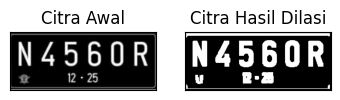

In [ ]:
#Dilasi tanpa library
def dilasi_citra(F, w):
    #size image
    p, q = F.shape
    imgD = np.zeros((p,q), dtype=np.uint8)
    #Generate structure element dilasi (SED)
    SED = np.ones((w,w), dtype=np.uint8)
    constant1 = (w-1)//2
    #Proses Dilasi
    for i in range(constant1, p-constant1):
        for j in range(constant1, q-constant1):
            temp = F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
            product = temp * SED
            imgD[i,j] = np.max(product)
    return imgD

img_d = cv2.imread('/content/drive/MyDrive/Citra/plat nomor.png', 0)
ret, thresh = cv2.threshold(img_d, 125, 200, cv2.THRESH_BINARY)
w = 5
imgD = dilasi_citra(thresh, w)

plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

[[1 1 1]
 [1 1 1]
 [1 1 1]]


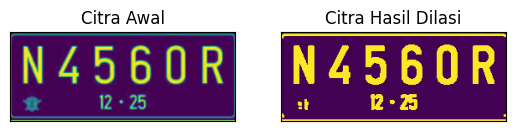

In [ ]:
img = cv2.imread('/content/drive/MyDrive/Citra/plat nomor.png', 0)
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3,3), np.uint16)
dilasi = cv2.dilate(thresh, kernel, iterations = 1)

print(kernel)
plt.subplot(121), plt.imshow(img), plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(dilasi), plt.title('Citra Hasil Dilasi')
plt.xticks([]), plt.yticks([])
plt.show()

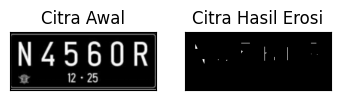

In [ ]:
#Erosi Tanpa Library
def erosi_citra(F, k):
    #size image
    m, n = F.shape
    #Generate structure element erosi (SE)
    SE = np.ones((k,k), dtype=np.uint8)
    constant = (k-1)//2
    imgE = np.zeros((m,n), dtype=np.uint8)
    #Proses Erosi
    for i in range(constant, m-constant):
        for j in range(constant, n-constant):
            temp = F[i-constant:i+constant+1, j-constant:j+constant+1]
            product = temp * SE
            imgE[i,j] = np.min(product)
    return imgE

img_e = cv2.imread('/content/drive/MyDrive/Citra/plat nomor.png', 0)
ret1, thresh1 = cv2.threshold(img_e, 175, 225, cv2.THRESH_BINARY)
k = 5
imgE = erosi_citra(thresh1, k)

plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

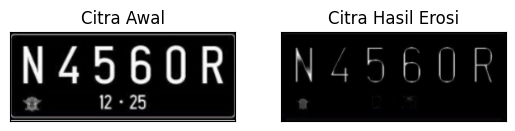

In [ ]:
#EROSI LIBRARY
img = cv2.imread('/content/drive/MyDrive/Citra/plat nomor.png')
kernel = np.ones((5,5), np.uint8)
erosion = cv2.erode(img, kernel, iterations = 1)

plt.subplot(121), plt.imshow(img), plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(erosion), plt.title('Citra Hasil Erosi')
plt.xticks([]), plt.yticks([])
plt.show()

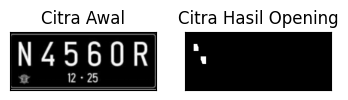

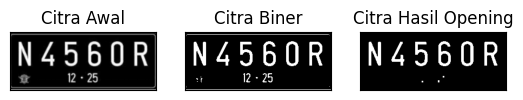

In [ ]:
# Operasi Opening tanpa Library Morphology
img_o = cv2.imread('/content/drive/MyDrive/Citra/plat nomor.png', 0)
reto, thresho = cv2.threshold(img_o, 127, 225, cv2.THRESH_BINARY)
k = 7
imgO = dilasi_citra(erosi_citra(thresho, k), k)

plt.subplot(131), plt.imshow(img_o, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgO, cmap='gray')
plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])
plt.show()

# Operasi Opening Menggunakan Library Morphology
img = cv2.imread('/content/drive/MyDrive/Citra/plat nomor.png', 0)
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3,3), np.uint8)
openn = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)

plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(openn, cmap='gray')
plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])
plt.show()

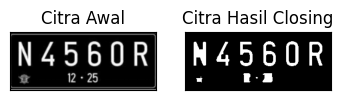

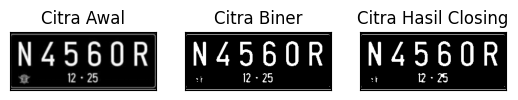

In [ ]:
# operasi closing tanpa library morphology
img_c = cv2.imread('/content/drive/MyDrive/Citra/plat nomor.png', 0)
retc, threshc = cv2.threshold(img_c, 127, 225, cv2.THRESH_BINARY)
k = 7
imgC = erosi_citra(dilasi_citra(threshc, k), k)

plt.subplot(131), plt.imshow(img_c, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgC, cmap='gray')
plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])
plt.show()

# operasi closing dengan library morphology
img = cv2.imread('/content/drive/MyDrive/Citra/plat nomor.png', 0)
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3,3), np.uint8)
closs = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)

plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(closs, cmap='gray')
plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])
plt.show()

SED = Cross 3


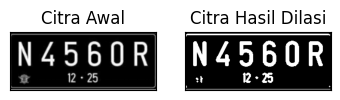

SED = Cross 5


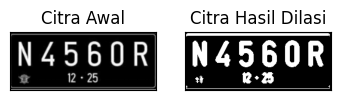

In [ ]:
#Dilasi Cross SED
def dilasi_citra(F, w):
    p, q = F.shape
    imgD = np.zeros((p,q), dtype=np.uint8)
    SED = np.array([[0, 1, 0],
                    [1, 1, 1],
                    [0, 1, 0]], dtype = np.uint8)
    constant1 = (w-1)//2
    for i in range(constant1, p-constant1):
        for j in range(constant1, q-constant1):
            temp = F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
            product = temp * SED
            imgD[i,j] = np.max(product)
    return imgD

print('SED = Cross 3')
img_d = cv2.imread('/content/drive/MyDrive/Citra/plat nomor.png', 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
w = 3
imgD = dilasi_citra(thresh, w)
plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

def dilasi_citra_5(F, w):
    p, q = F.shape
    imgD = np.zeros((p,q), dtype=np.uint8)
    SED = np.array([[0, 0, 1, 0, 0],
                    [0, 0, 1, 0, 0],
                    [1, 1, 1, 1, 1],
                    [0, 0, 1, 0, 0],
                    [0, 0, 1, 0, 0]], dtype = np.uint8)
    constant1 = (w-1)//2
    for i in range(constant1, p-constant1):
        for j in range(constant1, q-constant1):
            temp = F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
            product = temp * SED
            imgD[i,j] = np.max(product)
    return imgD

print('SED = Cross 5')
img_d = cv2.imread('/content/drive/MyDrive/Citra/plat nomor.png', 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
w = 5
imgD = dilasi_citra_5(thresh, w)
plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

SED = Circle 3


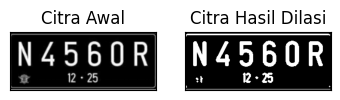

SED = Circle 5


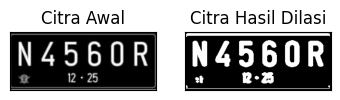

In [ ]:
#Dilasi Circular SED
def dilasi_citra_circ(F, w):
    p, q = F.shape
    imgD = np.zeros((p,q), dtype=np.uint8)
    SED = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (w,w))
    constant1 = (w-1)//2
    for i in range(constant1, p-constant1):
        for j in range(constant1, q-constant1):
            temp = F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
            product = temp * SED
            imgD[i,j] = np.max(product)
    return imgD

print('SED = Circle 3')
img_d = cv2.imread('/content/drive/MyDrive/Citra/plat nomor.png', 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
w = 3
imgD = dilasi_citra_circ(thresh, w)
plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

print('SED = Circle 5')
img_d = cv2.imread('/content/drive/MyDrive/Citra/plat nomor.png', 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
w = 5
imgD = dilasi_citra_circ(thresh, w)
plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

SE = Rectangle 3x5


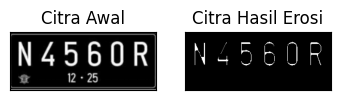

SE = Rectangle 5x7


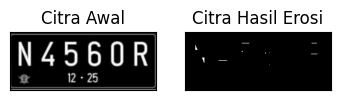

In [ ]:
#Erosi SE Rectangle
def erosi_citra_rect(F, p, l):
    m, n = F.shape
    SE = cv2.getStructuringElement(cv2.MORPH_RECT, (p,l))
    constant1 = (l-1)//2
    constant2 = (p-1)//2
    imgE = np.zeros((m,n), dtype=np.uint8)
    for i in range(constant1, m-constant1):
        for j in range(constant2, n-constant2):
            temp = F[i-constant1:i+constant1+1, j-constant2:j+constant2+1]
            product = temp * SE
            imgE[i,j] = np.min(product)
    return imgE

print('SE = Rectangle 3x5')
img_e = cv2.imread('/content/drive/MyDrive/Citra/plat nomor.png', 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
p = 5
l = 3
imgE = erosi_citra_rect(thresh1, p, l)
plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

print('SE = Rectangle 5x7')
img_e = cv2.imread('/content/drive/MyDrive/Citra/plat nomor.png', 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
p = 7
l = 5
imgE = erosi_citra_rect(thresh1, p, l)
plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

SE Line Vertikal 3


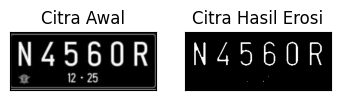

SE Line Vertikal 5


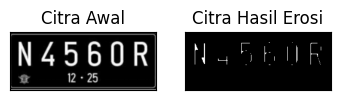

In [ ]:
#Erosi Line Vertikal SE
def erosi_citra_line(F, k):
    m, n = F.shape
    SE = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (1,k))
    constant = (k-1)//2
    imgE = np.zeros((m,n), dtype=np.uint8)
    for i in range(constant, m-constant):
        for j in range(constant, n-constant):
            temp = F[i-constant:i+constant+1, j-constant:j+constant+1]
            product = temp * SE
            imgE[i,j] = np.min(product)
    return imgE

print('SE Line Vertikal 3')
img_e =cv2.imread('/content/drive/MyDrive/Citra/plat nomor.png', 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
k = 3
imgE = erosi_citra_line(thresh1, k)
plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

print('SE Line Vertikal 5')
img_e = cv2.imread('/content/drive/MyDrive/Citra/plat nomor.png', 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
k = 5
imgE = erosi_citra_line(thresh1, k)
plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

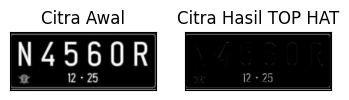

In [ ]:
#TopHat
filterSize = (3,3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)
img = cv2.imread('/content/drive/MyDrive/Citra/plat nomor.png')
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
tophat_img = cv2.morphologyEx(img, cv2.MORPH_TOPHAT, kernel)

plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(tophat_img, cmap='gray')
plt.title('Citra Hasil TOP HAT'), plt.xticks([]), plt.yticks([])
plt.show()

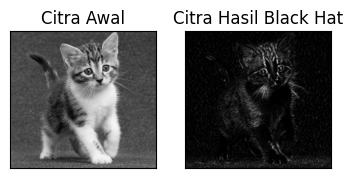

In [ ]:
# BLACKHAT
filterSize = (3,3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)
img = cv2.imread('/content/drive/MyDrive/Citra/kitten01.jpeg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
Kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (13, 5))
blackhat = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, Kernel)

plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(blackhat, cmap='gray')
plt.title('Citra Hasil Black Hat'), plt.xticks([]), plt.yticks([])
plt.show()

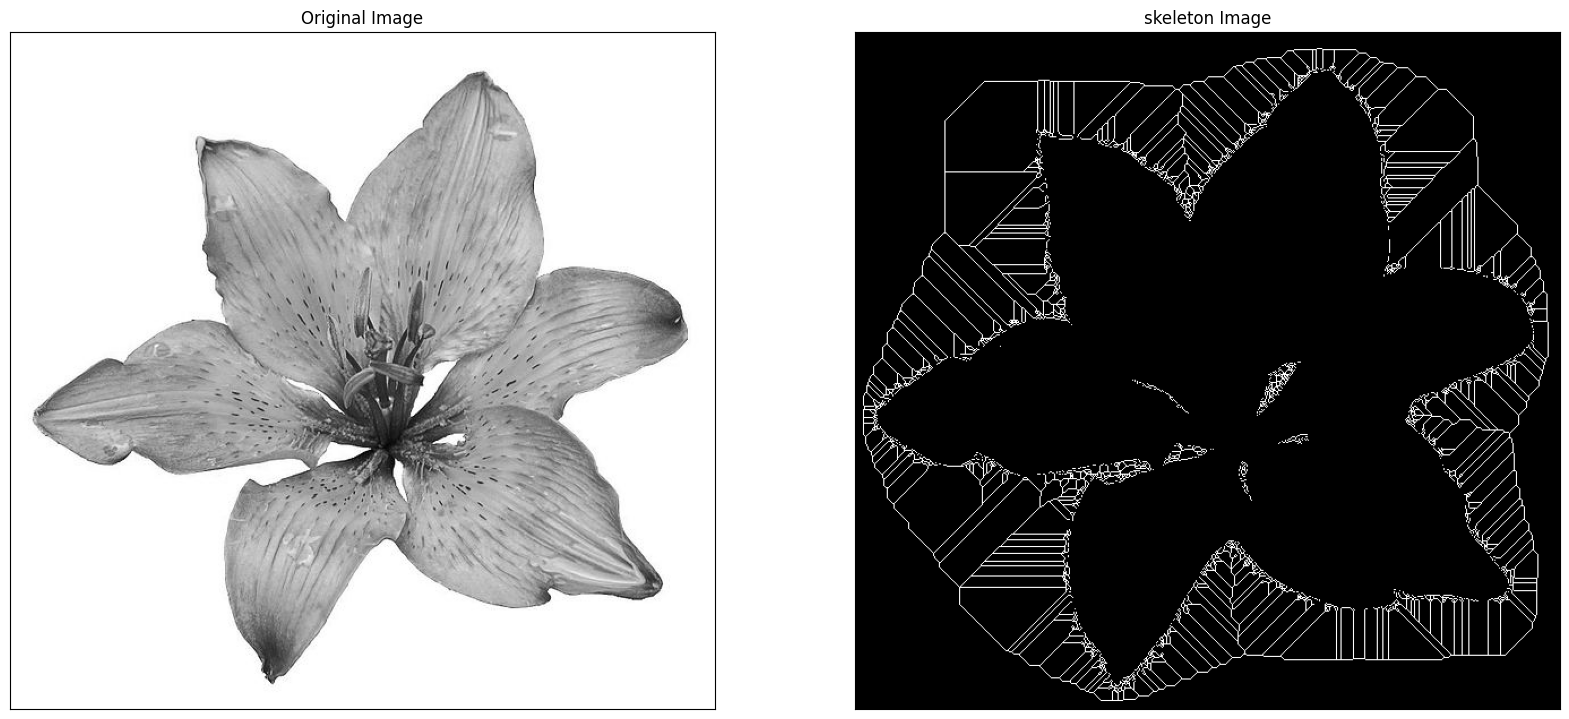

In [ ]:
# Skeleton
import cv2 as cv
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

img = cv.imread('/content/drive/MyDrive/Citra/lily.jpeg', 0)
binary = img > filters.threshold_triangle(img)
binary_cp = binary.copy()
binary_cp[binary_cp == True] = 1
binary_cp[binary_cp == False] = 0

skeleton = skeletonize(binary_cp)

plt.figure(figsize=(20,20))
plt.subplot(121), plt.imshow(img, cmap='gray')
plt.title('Original Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(skeleton, cmap='gray')
plt.title('skeleton Image'), plt.xticks([]), plt.yticks([])
plt.savefig("binary_and_bin_skeleton.png")
plt.show()

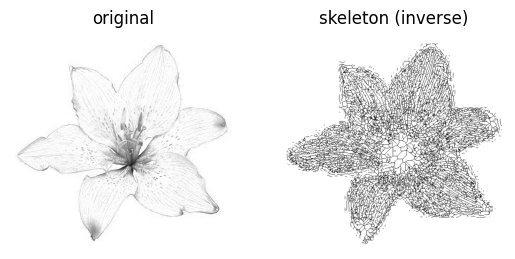

In [ ]:
# Skeleton Inverse
from skimage import io
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

img = io.imread('/content/drive/MyDrive/Citra/lily.jpeg')[..., 0]
binary = img < filters.threshold_triangle(img)
skeleton = skeletonize(binary)

fig, ax = plt.subplots(1, 2)
ax[0].imshow(img, cmap='gray')
ax[0].set_title('original')
ax[0].set_axis_off()
ax[1].imshow(skeleton, cmap='gray_r')
ax[1].set_title('skeleton (inverse)')
ax[1].set_axis_off()
plt.show()

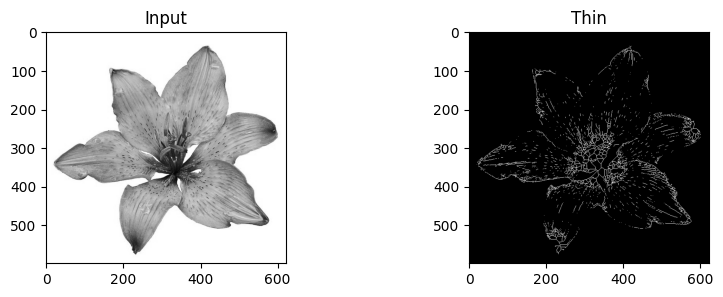

In [ ]:
# Thickening / Thinning (Perbaikan)
from skimage import img_as_float
from skimage import io, color, morphology
import matplotlib.pyplot as plt

image = img_as_float(color.rgb2gray(io.imread('/content/drive/MyDrive/Citra/lily.jpeg')))
# Memastikan citra biner yang benar (nilai boolean)
image_binary = image < 0.5

# Menggunakan thin dari skimage.morphology
out_thin = morphology.thin(image_binary)

f, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 3))
ax0.imshow(image, cmap='gray')
ax0.set_title('Input')
ax1.imshow(out_thin, cmap='gray')
ax1.set_title('Thin')
plt.savefig('/tmp/char_out.png')
plt.show()

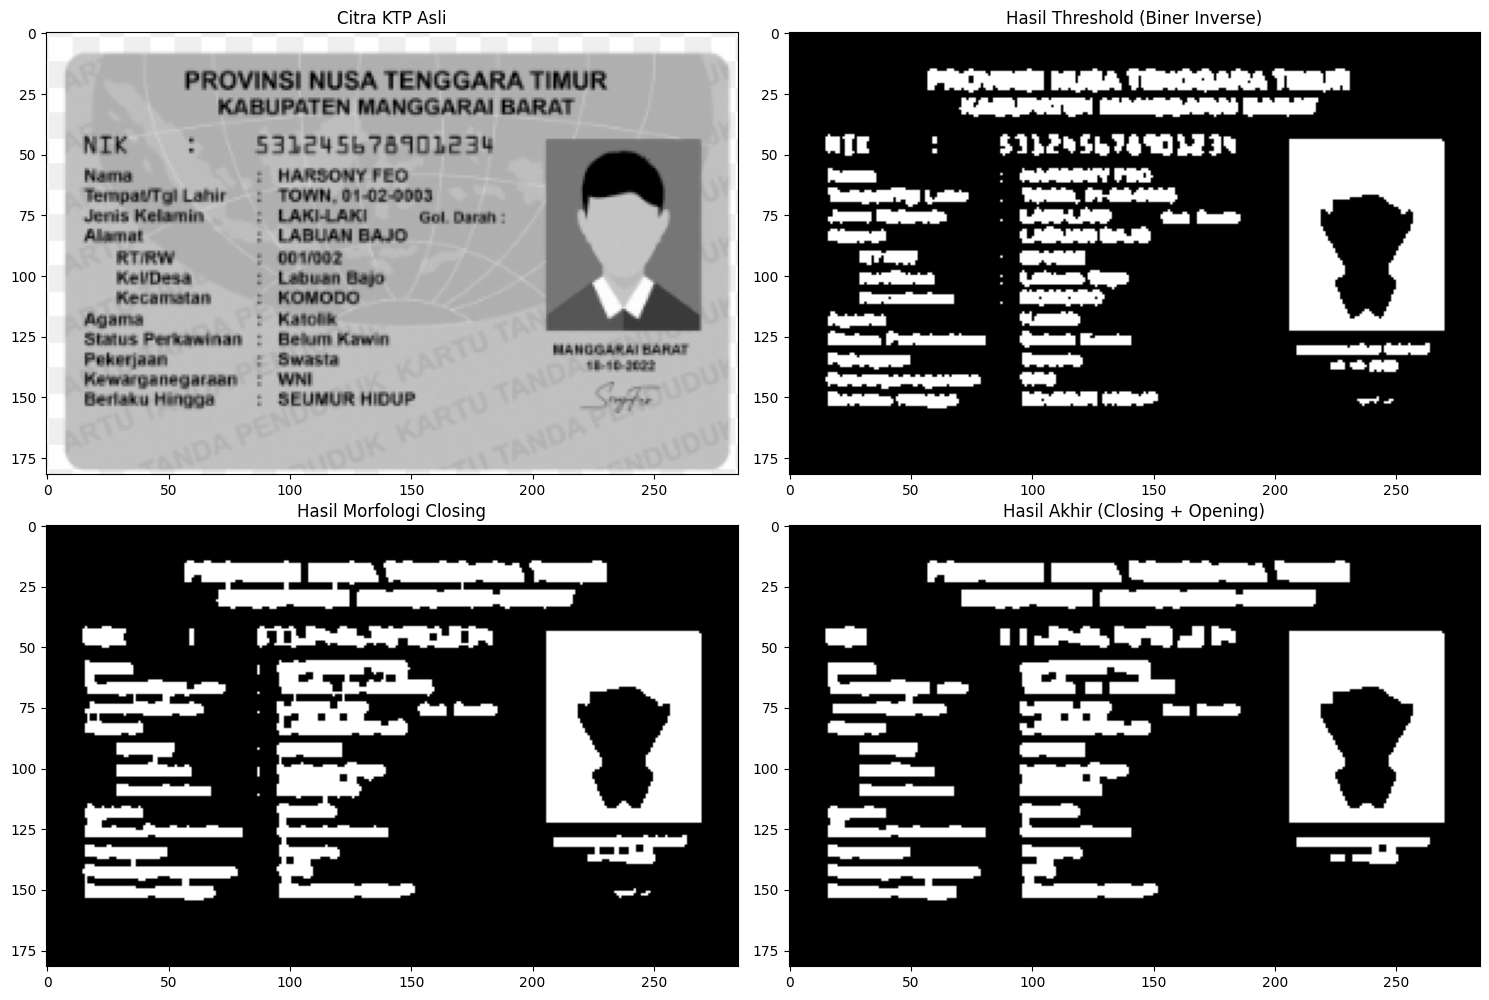

In [ ]:
# TUGAS PRAKTIKUM: Implementasi Morfologi pada Citra KTP
import cv2
import numpy as np
from matplotlib import pyplot as plt

# 1. Baca Citra KTP (Ubah path sesuai dengan lokasi dataset KTP Anda)
img_ktp = cv2.imread('/content/drive/MyDrive/Citra/ktp.png', 0)

# 2. Preprocessing: Blur ringan untuk mengurangi noise awal
blur = cv2.GaussianBlur(img_ktp, (3,3), 0)

# 3. Thresholding (Otsu atau Adaptive)
ret, thresh_ktp = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

# 4. Operasi Morfologi untuk memperjelas teks KTP
# Kita gunakan Rectangular Kernel karena teks cenderung berbentuk persegi panjang/garis
kernel_rect = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))

# a. Morphological Closing: Menyatukan bagian-bagian teks yang terputus
closing_ktp = cv2.morphologyEx(thresh_ktp, cv2.MORPH_CLOSE, kernel_rect)

# b. Morphological Opening (Opsional): Membersihkan noise titik-titik kecil di sekitar teks
opening_ktp = cv2.morphologyEx(closing_ktp, cv2.MORPH_OPEN, kernel_rect)

# 5. Tampilkan Hasil
plt.figure(figsize=(15, 10))
plt.subplot(221), plt.imshow(img_ktp, cmap='gray'), plt.title('Citra KTP Asli')
plt.subplot(222), plt.imshow(thresh_ktp, cmap='gray'), plt.title('Hasil Threshold (Biner Inverse)')
plt.subplot(223), plt.imshow(closing_ktp, cmap='gray'), plt.title('Hasil Morfologi Closing')
plt.subplot(224), plt.imshow(opening_ktp, cmap='gray'), plt.title('Hasil Akhir (Closing + Opening)')
plt.tight_layout()
plt.show()